# 01 · Activation Functions and a Hand-Built Feed-Forward Network

> Curated from my completed FIT3181 (Monash University) Assignment 1 notebook. Code cells and their outputs are unchanged from the original Google Colab run; only explanatory markdown has been rewritten. Cells marked *provided* are unit starter code.

**Contents**
1. ELU and GELU activations and their derivatives
2. A feed-forward network built from a custom `MyLinear` layer, trained on MNIST with three hand-written optimisers: SGD, SGD with momentum, and AdaGrad (no `torch.optim`)

## 1. ELU and GELU

$$\text{ELU}(x)=\begin{cases}0.1\,(e^{x}-1) & x\le 0\\ x & x>0\end{cases}\qquad
\text{ELU}'(x)=\begin{cases}0.1\,e^{x} & x<0\\ 1 & x>0\end{cases}$$

$$\text{GELU}(x)=x\,\Phi(x)\qquad \text{GELU}'(x)=\Phi(x)+x\,\phi(x)$$

With $\alpha = 0.1$, ELU's range is $(-0.1, \infty)$ and its derivative is discontinuous at $x=0$ (left limit $0.1$, right limit $1$), so the two branches of the derivative are plotted separately.

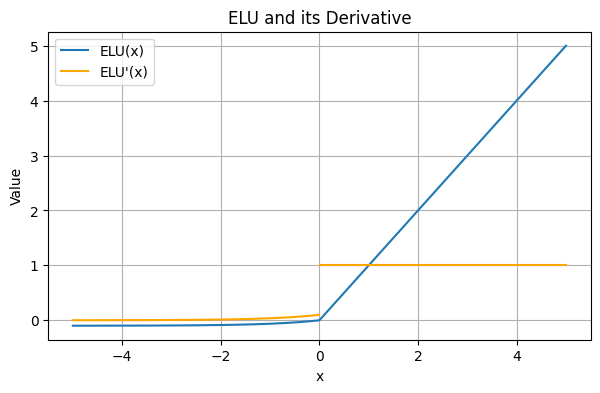

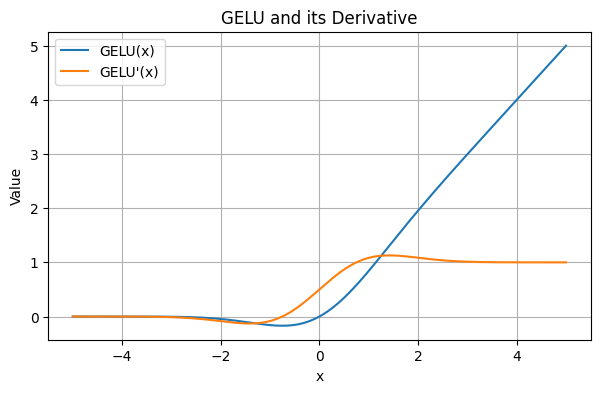

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# x values
x = np.linspace(-5, 5, 1000)

# ------------------------
# (a) ELU and derivative
# ------------------------

elu = np.where(x <= 0, 0.1 * (np.exp(x) - 1), x)

x_left = x[x < 0]
x_right = x[x > 0]

plt.figure(figsize=(7, 4))

# Activation function
plt.plot(x, elu, label="ELU(x)")

# Derivative as two separate branches
plt.plot(x_left, 0.1 * np.exp(x_left), label="ELU'(x)", color="orange")
plt.plot(x_right, np.ones_like(x_right), color="orange")

plt.title("ELU and its Derivative")
plt.xlabel("x")
plt.ylabel("Value")
plt.legend()
plt.grid(True)
plt.show()


# ------------------------
# (b) GELU and derivative
# ------------------------

Phi = norm.cdf(x)
phi = norm.pdf(x)

gelu = x * Phi
gelu_deriv = Phi + x * phi

plt.figure(figsize=(7, 4))

plt.plot(x, gelu, label="GELU(x)")
plt.plot(x, gelu_deriv, label="GELU'(x)")

plt.title("GELU and its Derivative")
plt.xlabel("x")
plt.ylabel("Value")
plt.legend()
plt.grid(True)
plt.show()


# Approximate minimum of GELU
min_index = np.argmin(gelu)

min_x = x[min_index]
min_y = gelu[min_index]


## 2. Feed-forward network from scratch (MNIST)

Data loading and flattening (*provided*).

In [ ]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

In [ ]:
transform = transforms.Compose([
    transforms.ToTensor(),  # Convert the image to a tensor with shape [C, H, W]
    transforms.Normalize((0.5,), (0.5,)),  # Normalize to [-1, 1]
    transforms.Lambda(lambda x: x.view(28*28)) # Flatten the tensor to shape [-1,HW]
])

# Load the MNIST dataset
train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_data, train_labels = train_dataset.data, train_dataset.targets
test_data, test_labels = test_dataset.data, test_dataset.targets
print(train_data.shape, train_labels.shape)
print(test_data.shape, test_labels.shape)

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 505kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.53MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.65MB/s]

torch.Size([60000, 28, 28]) torch.Size([60000])
torch.Size([10000, 28, 28]) torch.Size([10000])


In [ ]:
train_dataset.data = train_data.data.reshape(-1, 28*28)
test_dataset.data = test_data.data.reshape(-1, 28*28)

train_data, train_labels = train_dataset.data, train_dataset.targets
test_data, test_labels = test_dataset.data, test_dataset.targets
print(train_data.shape, train_labels.shape)
print(test_data.shape, test_labels.shape)

torch.Size([60000, 784]) torch.Size([60000])
torch.Size([10000, 784]) torch.Size([10000])


In [ ]:
train_loader = DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=64, shuffle=False)

### `MyLinear`: a linear layer with explicit parameters

The weights use He initialisation, $W \sim \mathcal{N}(0, 2/n_{in})$, which suits ReLU, and the biases start at zero.

In [ ]:
class MyLinear(torch.nn.Module):
  def __init__(self, input_size, output_size):
    """
    input_size: the size of the input
    output_size: the size of the output
    """
    super().__init__()
    #Your code here
    self.W = torch.nn.Parameter(
        torch.randn(input_size, output_size) *
        torch.sqrt(torch.tensor(2.0 / input_size))
    )

    self.b = torch.nn.Parameter(
        torch.zeros(output_size)
    )

  #forward propagation
  def forward(self, x): #x is a mini-batch
    return x @ self.W + self.b

### `MyFFN`: stacked layers plus three hand-written optimisers

The class signature and docstrings are *provided*. I implemented the network construction, the forward pass, and the three update rules. Gradients come from autograd, but every parameter update is written by hand under `torch.no_grad()`:

| Method | Update rule as implemented |
|---|---|
| `update_SGD` | $\theta \leftarrow \theta - \eta\, g$ |
| `update_SGDwithMomentum` | $v \leftarrow \mu\, g + (1-\mu)\, v,\quad \theta \leftarrow \theta - \eta\, v$ |
| `update_AdaGrad` | $\gamma \leftarrow \gamma + g^2,\quad \theta \leftarrow \theta - \dfrac{\eta}{\epsilon + \sqrt{\gamma}}\, g$ |

*Note:* layers are stored in a plain Python list rather than `nn.ModuleList`. Training is unaffected because the updates iterate over `self.layers` directly, but `print(myFFN)` and `myFFN.parameters()` do not show the layers.

In [ ]:
class MyFFN(torch.nn.Module):
  def __init__(self, input_size, num_classes, hidden_sizes, act = torch.nn.ReLU()):
    """
    input_size: the size of the input
    num_classes: the number of classes
    act is the activation function
    hidden_sizes is the list of hidden sizes
    for example input_size = 3, hidden_sizes = [5, 7], num_classes = 4, and act = torch.nn.ReLU()
    means that we are building up a FFN with the confirguration
    (3 (Input) -> 5 (ReLU) -> 7 (ReLU) -> 4 (Output))
    """
    super(MyFFN, self).__init__()
    self.input_size = input_size
    self.num_classes = num_classes
    self.act = act() if isinstance(act, type) else act
    self.hidden_sizes = hidden_sizes
    self.num_layers = len(hidden_sizes) + 1

  def create_FFN(self):
    """
    This function creates the feed-forward neural network
    We stack many MyLinear layers
    """
    hidden_sizes = [self.input_size] + self.hidden_sizes + [self.num_classes]
    self.layers = []

    for i in range(self.num_layers):
      layer = MyLinear(hidden_sizes[i], hidden_sizes[i + 1])
      self.layers.append(layer)


  def forward(self,x):
    """
    This implements the forward propagation of the batch x
    This needs to return the logits of x
    """
    for i, layer in enumerate(self.layers):
      x = layer(x)
      # Apply activation for all but the last layer
      if i < len(self.layers) - 1:
        x = self.act(x)
    return x

  def compute_loss(self, x, y):
    """
    This function computes the cross-entropy loss
    You can use the built-in CE loss of PyTorch
    """
    logits = self.forward(x)
    loss = torch.nn.functional.cross_entropy(logits, y)
    return loss

  def update_SGD(self, x, y, learning_rate = 0.01):
    """
    This function updates the model parameters using SGD using the batch (x,y)
    You need to implement the update rule manually and cannot rely on the built-in optimizer
    """
    # 1. Compute the loss for the current mini-batch
    loss = self.compute_loss(x, y)

    # 2. Compute gradients using PyTorch auto-differentiation
    loss.backward()

    # 3. Manually update W and b using SGD
    with torch.no_grad():
        for layer in self.layers:
            layer.W -= learning_rate * layer.W.grad
            layer.b -= learning_rate * layer.b.grad

    # 4. Clear the gradients before the next mini-batch
    for layer in self.layers:
        layer.W.grad.zero_()
        layer.b.grad.zero_()

  def update_SGDwithMomentum(self, x, y, learning_rate = 0.01, momentum = 0.9):
    """
    This function updates the model parameters using SGD with momentum using the batch (x,y)
    You need to implement the update rule manually and cannot rely on the built-in optimizer
    """

    # Initialize velocities only the first time this method is called
    if not hasattr(self, 'velocity_W'):
      self.velocity_W = [torch.zeros_like(layer.W) for layer in self.layers]
      self.velocity_b = [torch.zeros_like(layer.b) for layer in self.layers]

    # 1. Compute loss
    loss = self.compute_loss(x, y)

    # 2. Compute gradients
    loss.backward()

    # 3. Update velocities and parameters
    with torch.no_grad():
      for i, layer in enumerate(self.layers):

        self.velocity_W[i] = (
            momentum * layer.W.grad + (1 - momentum) * self.velocity_W[i]
        )

        self.velocity_b[i] = (
             momentum * layer.b.grad + (1 - momentum) * self.velocity_b[i]
        )

        layer.W -= learning_rate * self.velocity_W[i]
        layer.b -= learning_rate * self.velocity_b[i]

    # 4. Clear gradients
    for layer in self.layers:
      if layer.W.grad is not None:
        layer.W.grad.zero_()
      if layer.b.grad is not None:
        layer.b.grad.zero_()

  def update_AdaGrad(self, x, y, learning_rate = 0.01):
    """
    This function updates the model parameters using AdaGrad using the batch (x,y)
    You need to implement the update rule manually and cannot rely on the built-in optimizer
    """
    epsilon = 1e-6

    # Initialise accumulated squared gradients only once
    if not hasattr(self, 'gamma_W'):
      self.gamma_W = [torch.zeros_like(layer.W) for layer in self.layers]
      self.gamma_b = [torch.zeros_like(layer.b) for layer in self.layers]

    # 1. Compute loss
    loss = self.compute_loss(x, y)

    # 2. Compute gradients
    loss.backward()

    # 3. Accumulate squared gradients and update parameters
    with torch.no_grad():
      for i, layer in enumerate(self.layers):

        self.gamma_W[i] += layer.W.grad ** 2
        self.gamma_b[i] += layer.b.grad ** 2

        layer.W -= learning_rate / (epsilon + torch.sqrt(self.gamma_W[i])) * layer.W.grad
        layer.b -= learning_rate / (epsilon + torch.sqrt(self.gamma_b[i])) * layer.b.grad

    # 4. Clear gradients
    for layer in self.layers:
      if layer.W.grad is not None:
        layer.W.grad.zero_()
      if layer.b.grad is not None:
        layer.b.grad.zero_()

In [ ]:
myFFN = MyFFN(input_size = 28*28, num_classes = 10, hidden_sizes = [100, 100], act = torch.nn.ReLU)
myFFN.create_FFN()
print(myFFN)

MyFFN(
  (act): ReLU()
)


### Evaluation helpers

In [ ]:
def compute_acc(model, data_loader):
  """
  This function computes the accuracy of the model on a data loader
  """
  model.eval()

  correct = 0
  total = 0

  with torch.no_grad():
    for x, y in data_loader:
      logits = model(x)
      predicted = torch.argmax(logits, dim=1)

      correct += (predicted ==y).sum().item()
      total += y.size(0)

  accuracy = correct / total

  return accuracy

In [ ]:
def compute_loss(model, data_loader):
  """
  This function computes the loss of the model on a data loader
  """
  model.eval()

  total_loss = 0

  with torch.no_grad():
    for x, y in data_loader:
      loss = model.compute_loss(x, y)
      total_loss += loss.item()

  average_loss = total_loss / len(data_loader)

  return average_loss


### Training: SGD (η = 0.01, batch 64, 50 epochs)

No validation split is used in this section; test-set metrics are logged after every epoch.

In [ ]:
num_epochs = 50
for epoch in range(num_epochs):
    for i, (x, y) in enumerate(train_loader):
      myFFN.update_SGD(x, y, learning_rate = 0.01)
    train_acc = compute_acc(myFFN, train_loader)
    train_loss = compute_loss(myFFN, train_loader)
    test_acc = compute_acc(myFFN, test_loader)
    test_loss = compute_loss(myFFN, test_loader)
    print(f"Epoch {epoch+1}/{num_epochs}, Train Loss: {train_loss:.4f}, Train Acc: {train_acc*100:.2f}%, Test Loss: {test_loss:.4f}, Test Acc: {test_acc*100:.2f}%")

Epoch 1/50, Train Loss: 0.3534, Train Acc: 89.35%, Test Loss: 0.3399, Test Acc: 89.98%
Epoch 2/50, Train Loss: 0.2722, Train Acc: 91.68%, Test Loss: 0.2651, Test Acc: 92.18%
Epoch 3/50, Train Loss: 0.2233, Train Acc: 93.63%, Test Loss: 0.2242, Test Acc: 93.53%
Epoch 4/50, Train Loss: 0.2170, Train Acc: 93.68%, Test Loss: 0.2181, Test Acc: 93.36%
Epoch 5/50, Train Loss: 0.1723, Train Acc: 95.13%, Test Loss: 0.1792, Test Acc: 94.86%
Epoch 6/50, Train Loss: 0.1671, Train Acc: 95.23%, Test Loss: 0.1749, Test Acc: 94.80%
Epoch 7/50, Train Loss: 0.1506, Train Acc: 95.64%, Test Loss: 0.1586, Test Acc: 95.36%
Epoch 8/50, Train Loss: 0.1309, Train Acc: 96.22%, Test Loss: 0.1445, Test Acc: 95.79%
Epoch 9/50, Train Loss: 0.1213, Train Acc: 96.53%, Test Loss: 0.1353, Test Acc: 96.05%
Epoch 10/50, Train Loss: 0.1237, Train Acc: 96.38%, Test Loss: 0.1406, Test Acc: 95.81%
Epoch 11/50, Train Loss: 0.1097, Train Acc: 96.81%, Test Loss: 0.1295, Test Acc: 96.06%
Epoch 12/50, Train Loss: 0.1024, Train Ac

### Training: SGD with momentum (η = 0.01, μ = 0.9, 50 epochs)

In [ ]:
# Create a fresh model for SGD with momentum
myFFN_momentum = MyFFN(
    input_size=28*28,
    num_classes=10,
    hidden_sizes=[100, 100],
    act=torch.nn.ReLU()
)

myFFN_momentum.create_FFN()

# Train for 50 epochs using SGD with Momentum
num_epochs = 50

for epoch in range(num_epochs):
  for i, (x, y) in enumerate(train_loader):
    myFFN_momentum.update_SGDwithMomentum(x, y, learning_rate=0.01, momentum=0.9)

  train_acc = compute_acc(myFFN_momentum, train_loader)
  train_loss = compute_loss(myFFN_momentum, train_loader)

  test_acc = compute_acc(myFFN_momentum, test_loader)
  test_loss = compute_loss(myFFN_momentum, test_loader)

  print(
      f"Epoch {epoch+1}/{num_epochs}, "
      f"Train Loss: {train_loss:.4f}, "
      f"Train Acc: {train_acc*100:.2f}%, "
      f"Test Loss: {test_loss:.4f}, "
      f"Test Acc: {test_acc*100:.2f}%"
  )

Epoch 1/50, Train Loss: 0.3258, Train Acc: 90.51%, Test Loss: 0.3103, Test Acc: 90.86%
Epoch 2/50, Train Loss: 0.2639, Train Acc: 92.31%, Test Loss: 0.2611, Test Acc: 92.59%
Epoch 3/50, Train Loss: 0.2326, Train Acc: 93.34%, Test Loss: 0.2357, Test Acc: 93.28%
Epoch 4/50, Train Loss: 0.1961, Train Acc: 94.28%, Test Loss: 0.2007, Test Acc: 93.91%
Epoch 5/50, Train Loss: 0.1927, Train Acc: 94.27%, Test Loss: 0.2024, Test Acc: 93.83%
Epoch 6/50, Train Loss: 0.1665, Train Acc: 95.28%, Test Loss: 0.1763, Test Acc: 94.76%
Epoch 7/50, Train Loss: 0.1492, Train Acc: 95.58%, Test Loss: 0.1593, Test Acc: 95.26%
Epoch 8/50, Train Loss: 0.1398, Train Acc: 95.93%, Test Loss: 0.1524, Test Acc: 95.28%
Epoch 9/50, Train Loss: 0.1285, Train Acc: 96.32%, Test Loss: 0.1444, Test Acc: 95.67%
Epoch 10/50, Train Loss: 0.1210, Train Acc: 96.59%, Test Loss: 0.1376, Test Acc: 95.89%
Epoch 11/50, Train Loss: 0.1187, Train Acc: 96.58%, Test Loss: 0.1367, Test Acc: 95.81%
Epoch 12/50, Train Loss: 0.1127, Train Ac

### Training: AdaGrad (η = 0.01, 50 epochs)

In [ ]:
# Create a fresh model for AdaGrad
myFFN_adagrad = MyFFN(
    input_size=28*28,
    num_classes=10,
    hidden_sizes=[100, 100],
    act=torch.nn.ReLU()
)

myFFN_adagrad.create_FFN()

# Train for 50 epochs using AdaGrad
num_epochs = 50

for epoch in range(num_epochs):
  for i, (x, y) in enumerate(train_loader):
    myFFN_adagrad.update_AdaGrad(x, y, learning_rate=0.01)

  train_acc = compute_acc(myFFN_adagrad, train_loader)
  train_loss = compute_loss(myFFN_adagrad, train_loader)

  test_acc = compute_acc(myFFN_adagrad, test_loader)
  test_loss = compute_loss(myFFN_adagrad, test_loader)

  print(
      f"Epoch {epoch+1}/{num_epochs}, "
      f"Train Loss: {train_loss:.4f}, "
      f"Train Acc: {train_acc*100:.2f}%, "
      f"Test Loss: {test_loss:.4f}, "
      f"Test Acc: {test_acc*100:.2f}%"
  )

Epoch 1/50, Train Loss: 0.2601, Train Acc: 92.44%, Test Loss: 0.2533, Test Acc: 92.86%
Epoch 2/50, Train Loss: 0.1969, Train Acc: 94.15%, Test Loss: 0.1974, Test Acc: 94.02%
Epoch 3/50, Train Loss: 0.1763, Train Acc: 94.88%, Test Loss: 0.1836, Test Acc: 94.44%
Epoch 4/50, Train Loss: 0.1556, Train Acc: 95.62%, Test Loss: 0.1638, Test Acc: 95.29%
Epoch 5/50, Train Loss: 0.1431, Train Acc: 95.85%, Test Loss: 0.1524, Test Acc: 95.36%
Epoch 6/50, Train Loss: 0.1307, Train Acc: 96.21%, Test Loss: 0.1427, Test Acc: 95.72%
Epoch 7/50, Train Loss: 0.1234, Train Acc: 96.45%, Test Loss: 0.1388, Test Acc: 95.76%
Epoch 8/50, Train Loss: 0.1183, Train Acc: 96.55%, Test Loss: 0.1319, Test Acc: 95.87%
Epoch 9/50, Train Loss: 0.1112, Train Acc: 96.77%, Test Loss: 0.1288, Test Acc: 96.18%
Epoch 10/50, Train Loss: 0.1091, Train Acc: 96.87%, Test Loss: 0.1273, Test Acc: 96.24%
Epoch 11/50, Train Loss: 0.1049, Train Acc: 96.97%, Test Loss: 0.1255, Test Acc: 96.27%
Epoch 12/50, Train Loss: 0.0992, Train Ac